<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter4/pinn_1_hidden_layer_15secs_150000fun.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1 Hidden Layer PINN to solve the pendulum equation for the first 15 secs using increased maxfun=150,000.
Drop angle is π/4 = 45◦ from rest.

Starting training with SciPy L-BFGS-B optimizer...


/tmp/ipykernel_1221/1911315337.py:96: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  res = minimize(


1-Layer Network | Iteration   1 | Loss: 0.311288
1-Layer Network | Iteration   2 | Loss: 0.212897
1-Layer Network | Iteration   3 | Loss: 0.134142
1-Layer Network | Iteration   4 | Loss: 0.123219
1-Layer Network | Iteration   5 | Loss: 0.119544
1-Layer Network | Iteration   6 | Loss: 0.119265
1-Layer Network | Iteration   7 | Loss: 0.119257
1-Layer Network | Iteration   8 | Loss: 0.119174
1-Layer Network | Iteration   9 | Loss: 0.119015
1-Layer Network | Iteration  10 | Loss: 0.118598
1-Layer Network | Iteration  11 | Loss: 0.118048
1-Layer Network | Iteration  12 | Loss: 0.116955
1-Layer Network | Iteration  13 | Loss: 0.113640
1-Layer Network | Iteration  14 | Loss: 0.106881
1-Layer Network | Iteration  15 | Loss: 0.102782
1-Layer Network | Iteration  16 | Loss: 0.096739
1-Layer Network | Iteration  17 | Loss: 0.093769
1-Layer Network | Iteration  18 | Loss: 0.092697
1-Layer Network | Iteration  19 | Loss: 0.091754
1-Layer Network | Iteration  20 | Loss: 0.091741
1-Layer Network | It

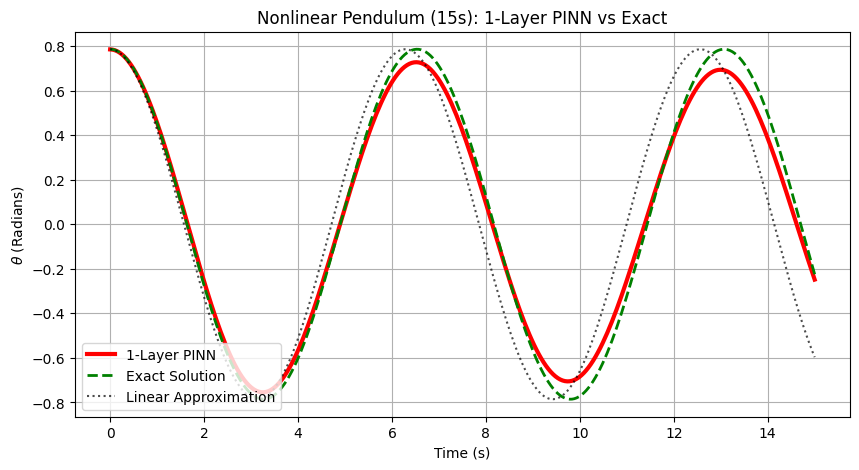

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import scipy.special as sp

class PureNumpyPINN:
    def __init__(self, n_hidden=32):
        self.H = n_hidden

        # 1. Initialize Weights and Biases (Glorot/Xavier style)
        self.W1 = np.random.randn(1, self.H) * np.sqrt(2.0 / (1 + self.H))
        self.b1 = np.zeros((1, self.H))

        self.W2 = np.random.randn(self.H, 1) * np.sqrt(2.0 / (self.H + 1))
        self.b2 = np.zeros((1, 1))

    def pack_weights(self):
        """Flattens all weights and biases into a single 1D array for SciPy."""
        flat_list = [w.flatten() for w in self.W1]
        flat_list.extend([w.flatten() for w in self.W2])
        flat_list.extend([b.flatten() for b in self.b1])
        flat_list.extend([b.flatten() for b in self.b2])
        return np.concatenate(flat_list)

    def unpack_weights(self, params):
        """Reconstructs the weight matrices from the SciPy 1D array."""
        idx = 0
        self.W1 = params[idx : idx+self.H].reshape(1, self.H); idx += self.H
        self.b1 = params[idx : idx+self.H].reshape(1, self.H); idx += self.H
        self.W2 = params[idx : idx+self.H].reshape(self.H, 1); idx += self.H
        self.b2 = params[idx : idx+1].reshape(1, 1)

    def forward_with_physics(self, t):
        """Calculates position, velocity, and acceleration analytically."""
        # --- TIME SCALING ---
        # Scale t from [0, 15] down to tau [0, 1]
        t_max = 15.0
        tau = t / t_max
        dtau_dt = 1.0 / t_max

        # 1. Feed-Forward
        z = np.dot(tau, self.W1) + self.b1
        a = np.tanh(z)
        theta = np.dot(a, self.W2) + self.b2

        # 2. First Derivative (Velocity)
        da_dtau = (1 - a**2) * self.W1
        velocity = np.dot(da_dtau, self.W2) * dtau_dt

        # 3. Second Derivative (Acceleration)
        d2a_dtau2 = -2 * a * (1 - a**2) * (self.W1**2)
        acceleration = np.dot(d2a_dtau2, self.W2) * (dtau_dt**2)

        return theta, velocity, acceleration

    def compute_loss(self, params, t_domain, t_ic, theta_0, omega_0):
        """Calculates the total error (Physics + Initial Conditions)."""
        self.unpack_weights(params)

        # Physics Loss
        theta, _, acceleration = self.forward_with_physics(t_domain)
        residual = acceleration + np.sin(theta)
        loss_ode = np.mean(residual**2)

        # Initial Condition Loss
        theta_pred_ic, velocity_pred_ic, _ = self.forward_with_physics(t_ic)
        loss_ic_position = np.mean((theta_pred_ic - theta_0)**2)
        loss_ic_velocity = np.mean((velocity_pred_ic - omega_0)**2)

        total_loss = loss_ode + loss_ic_position + loss_ic_velocity
        return total_loss

# ==========================================
# Training Setup (15 Seconds)
# ==========================================

t_domain = np.linspace(0, 15, 300).reshape(-1, 1)
t_ic = np.array([[0.0]])
theta_0 = np.pi / 4
omega_0 = 0.0

pinn = PureNumpyPINN(n_hidden=32)
initial_weights = pinn.pack_weights()

# --- Callback for Progress Tracking ---
progress = {'iterations': 0}

def monitor_progress(xk):
    progress['iterations'] += 1
    # Note: L-BFGS-B calls this after every major step, not every evaluation.
    current_loss = pinn.compute_loss(xk, t_domain, t_ic, theta_0, omega_0)
    print(f"1-Layer Network | Iteration {progress['iterations']:3d} | Loss: {current_loss:.6f}")

print("Starting training with SciPy L-BFGS-B optimizer...")

res = minimize(
    fun=pinn.compute_loss,
    x0=initial_weights,
    args=(t_domain, t_ic, theta_0, omega_0),
    method='L-BFGS-B',
    jac='2-point',
    callback=monitor_progress,
    options={'maxiter': 5000, 'maxfun': 100000, 'disp': False}
)

pinn.unpack_weights(res.x)
print(f"\nTraining Complete! Final Loss: {res.fun:.6f}")

# ==========================================
# Evaluation and Plotting
# ==========================================

theta_predicted, _, _ = pinn.forward_with_physics(t_domain)

k = np.sin(theta_0 / 2)
m = k**2
sn, cn, dn, ph = sp.ellipj(t_domain.flatten(), m)
cd = cn / dn
exact_solution = 2 * np.arcsin(k * cd)
linear_solution = theta_0 * np.cos(t_domain.flatten())

plt.figure(figsize=(10, 5))
plt.plot(t_domain, theta_predicted, 'r-', linewidth=3, label='1-Layer PINN')
plt.plot(t_domain, exact_solution, 'g--', linewidth=2, label='Exact Solution')
plt.plot(t_domain, linear_solution, 'k:', alpha=0.7, label='Linear Approximation')

plt.title("Nonlinear Pendulum (15s): 1-Layer PINN vs Exact")
plt.xlabel("Time (s)")
plt.ylabel("$\\theta$ (Radians)")
plt.legend(loc='lower left')
plt.grid(True)
plt.show()